# PBL JS03 - Ekstraksi Fitur, Seleksi Fitur, dan Splitting Data

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js03-ektraksi-fitur)

Notebook ini menerapkan langkah-langkah jobsheet JS03 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS03 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - Ekstraksi fitur data terstruktur | 28 fitur leksikal dari string URL |
| Praktikum 2 - Seleksi fitur | Variance threshold, ANOVA F, mutual information, SelectKBest |
| Praktikum 3 - Splitting data: random, stratified, cross validation | Pengaruh split pada kelas langka `Exploit` dan `spam` |
| Praktikum 4 - Ekstraksi fitur data tidak terstruktur | Bag-of-words token dan TF-IDF n-gram karakter |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Praktikum 1 - Ekstraksi Fitur Data Terstruktur

In [2]:
df = pbl_url.load_urls()
print(df.shape)
df.head()

(783705, 2)


,url,type
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


In [3]:
t0 = time.perf_counter()
X = pbl_url.lexical_features(df['url'])
y = df['type'].to_numpy()
print(f'{X.shape[1]} fitur, {time.perf_counter() - t0:.1f} detik')
pd.concat([df.head(3), X.head(3)], axis=1).T

28 fitur, 18.8 detik


,0,1,2
url,mp3raid.com/music/krizz_kaliko.html,bopsecrets.org/rexroth/cr/1.htm,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...
type,benign,benign,benign
url_len,35,31,111
host_len,11,14,11
path_len,23,16,99
query_len,0,0,0
n_dots,2,2,2
n_hyphens,0,0,16
n_underscores,1,0,0
n_slashes,2,3,3


Kelompok fitur yang diekstraksi:
* **Panjang:** `url_len`, `host_len`, `path_len`, `query_len`, `tld_len`, `path_depth`.
* **Hitungan karakter khusus:** titik, tanda hubung, garis bawah, garis miring, `?`, `=`, `&`, `@`, `%`, dan digit.
* **Rasio dan keacakan:** `digit_ratio`, `letter_ratio`, `entropy`, `host_entropy` (entropi Shannon).
* **Indikator biner:** host berupa IP, port, layanan pemendek URL, ekstensi executable, `.php`, `.htm`.
* **Leksikon:** jumlah kata mencurigakan (`login`, `verify`, `paypal`, ...) sesuai Garera dkk. (2007).

## Praktikum 2 - Seleksi Fitur

Fitur dengan varians ~0: []


,ANOVA_F,mutual_info
path_len,4271.2768,0.1681
host_entropy,4822.6362,0.1660
letter_ratio,24485.3851,0.1580
digit_ratio,23509.9757,0.1552
entropy,9447.6260,0.1176
query_len,3747.1401,0.0940
n_equals,30258.3613,0.0917
url_len,2469.2485,0.0915
n_ampersand,27160.0653,0.0886
tld_len,5506.1211,0.0819


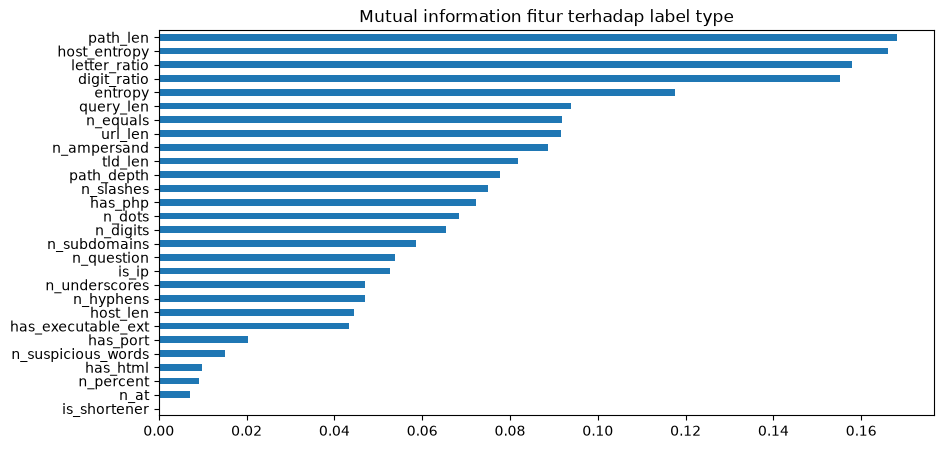

In [4]:
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif, SelectKBest
vt = VarianceThreshold(threshold=1e-4).fit(X)
print('Fitur dengan varians ~0:', list(X.columns[~vt.get_support()]))

sample = np.random.RandomState(42).choice(len(X), 60000, replace=False)
F, p = f_classif(X, y)
mi = mutual_info_classif(X.iloc[sample], y[sample], random_state=42)
score = pd.DataFrame({'ANOVA_F': F, 'mutual_info': mi}, index=X.columns).sort_values('mutual_info', ascending=False)
display(score.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
score['mutual_info'].plot.barh(ax=ax); ax.invert_yaxis(); ax.set_title('Mutual information fitur terhadap label type'); plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sub = np.random.RandomState(0).choice(len(Xtr), 150000, replace=False)
rows = []
for k in [5, 10, 15, 20, X.shape[1]]:
    cols = score.index[:k]
    rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(Xtr.iloc[sub][cols], ytr[sub])
    p_ = rf.predict(Xte[cols])
    rows.append({'k_fitur (top MI)': k, 'accuracy': accuracy_score(yte, p_), 'macro_F1': f1_score(yte, p_, average='macro')})
sel = pd.DataFrame(rows); sel.round(4)

,k_fitur (top MI),accuracy,macro_F1
0,5,0.7336,0.5608
1,10,0.7728,0.5967
2,15,0.8055,0.6275
3,20,0.8149,0.6498
4,28,0.8287,0.6643


## Praktikum 3 - Splitting Data

In [6]:
from sklearn.model_selection import StratifiedKFold, KFold
rare = ['Exploit', 'spam', 'legitimate']
def proportions(idx_sets, names):
    return pd.DataFrame({n: pd.Series(y[i]).value_counts(normalize=True).reindex(pbl_url.CLASSES).fillna(0) * 100 for n, i in zip(names, idx_sets)}).round(4)

sub = np.random.RandomState(7).choice(len(y), 5000, replace=False)   # dataset kecil untuk memperlihatkan efek split
ys = y[sub]
_, te_r = train_test_split(np.arange(len(ys)), test_size=0.2, random_state=3)
_, te_s = train_test_split(np.arange(len(ys)), test_size=0.2, stratify=ys, random_state=3)
print('Jumlah per kelas pada sampel 5.000:', pd.Series(ys).value_counts().to_dict())
tbl = pd.DataFrame({'populasi_%': pd.Series(ys).value_counts(normalize=True) * 100,
                    'random_test_%': pd.Series(ys[te_r]).value_counts(normalize=True) * 100,
                    'stratified_test_%': pd.Series(ys[te_s]).value_counts(normalize=True) * 100}).reindex(pbl_url.CLASSES).fillna(0).round(3)
tbl

Jumlah per kelas pada sampel 5.000: {'benign': 2740, 'phishing': 1435, 'defacement': 626, 'malware': 145, 'legitimate': 39, 'spam': 12, 'Exploit': 3}


,populasi_%,random_test_%,stratified_test_%
benign,54.80,56.0,54.8
legitimate,0.78,0.8,0.8
defacement,12.52,11.4,12.5
phishing,28.70,28.7,28.7
malware,2.90,2.6,2.9
spam,0.24,0.3,0.2
Exploit,0.06,0.2,0.1


In [7]:
def fold_counts(splitter):
    return [int((ys[te] == 'Exploit').sum()) for _, te in splitter.split(np.zeros(len(ys)), ys)]
print('Jumlah Exploit per fold, KFold biasa      :', fold_counts(KFold(5, shuffle=True, random_state=0)))
print('Jumlah Exploit per fold, StratifiedKFold  :', fold_counts(StratifiedKFold(5, shuffle=True, random_state=0)))

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
sub2 = np.random.RandomState(1).choice(len(y), 40000, replace=False)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv = cross_val_score(pipe, X.iloc[sub2], y[sub2], cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring='f1_macro', n_jobs=-1)
print('5-fold stratified CV macro-F1 (LogReg, 40k sampel):', cv.round(4), 'rata-rata', cv.mean().round(4), '± ', cv.std().round(4))

Jumlah Exploit per fold, KFold biasa      : [1, 0, 0, 2, 0]
Jumlah Exploit per fold, StratifiedKFold  : [1, 1, 1, 0, 0]


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


5-fold stratified CV macro-F1 (LogReg, 40k sampel): [0.3876 0.3883 0.3873 0.3883 0.391 ] rata-rata 0.3885 ±  0.0013


## Praktikum 4 - Ekstraksi Fitur Data Tidak Terstruktur (teks URL)

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import SGDClassifier
url_tr, url_te, yt_tr, yt_te = train_test_split(df['url'], y, test_size=0.2, stratify=y, random_state=42)
reps = {
    'Bag-of-words token (CountVectorizer)': CountVectorizer(token_pattern=r'[a-z0-9]+', min_df=2, max_features=200000),
    'TF-IDF token': TfidfVectorizer(token_pattern=r'[a-z0-9]+', min_df=2, max_features=200000, sublinear_tf=True),
    'TF-IDF n-gram karakter 3-5': TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=300000, sublinear_tf=True),
}
rows = []
for name, vec in reps.items():
    t0 = time.perf_counter(); Xt = vec.fit_transform(url_tr); Xv = vec.transform(url_te); t_ext = time.perf_counter() - t0
    clf = SGDClassifier(loss='modified_huber', alpha=1e-6, max_iter=15, random_state=42, n_jobs=-1).fit(Xt, yt_tr)
    p_ = clf.predict(Xv)
    rows.append({'representasi': name, 'dimensi': Xt.shape[1], 'nnz_per_url': Xt.nnz / Xt.shape[0], 'waktu_ekstraksi_s': t_ext,
                 'accuracy': accuracy_score(yt_te, p_), 'macro_F1': f1_score(yt_te, p_, average='macro')})
rf_all = sel.iloc[-1]
rows.append({'representasi': '28 fitur leksikal (Random Forest, dari Praktikum 2)', 'dimensi': X.shape[1], 'nnz_per_url': X.shape[1],
             'waktu_ekstraksi_s': np.nan, 'accuracy': rf_all['accuracy'], 'macro_F1': rf_all['macro_F1']})
pd.DataFrame(rows).set_index('representasi').round(4)

/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,dimensi,nnz_per_url,waktu_ekstraksi_s,accuracy,macro_F1
representasi,,,,,
Bag-of-words token (CountVectorizer),144380,7.2295,2.9208,0.9126,0.7889
TF-IDF token,144380,7.2295,3.0808,0.9094,0.7949
TF-IDF n-gram karakter 3-5,300000,129.1373,47.2692,0.9362,0.8434
"28 fitur leksikal (Random Forest, dari Praktikum 2)",28,28.0000,NaN,0.8287,0.6643


## Analisis

**Ekstraksi dan seleksi fitur.** Tidak ada fitur yang variansnya mendekati nol, tetapi `is_shortener` memiliki mutual information 0, sehingga hampir tidak informatif pada dataset ini. Kedua metode seleksi memberi peringkat yang berbeda:
* **ANOVA F** tertinggi untuk fitur biner yang memisahkan **satu kelas kecil** dengan tajam, yaitu `is_ip` (F = 73.628) dan `has_executable_ext` (65.663) untuk Exploit/malware.
* **Mutual information** tertinggi untuk fitur kontinu yang informatif **di semua kelas**: `path_len` (0,168), `host_entropy` (0,166), `letter_ratio`, dan `digit_ratio`.

Perbedaan ini sesuai dengan Guyon & Elisseeff (2003): uji F mengukur perbedaan rata-rata linier antarkelas, sedangkan MI menangkap ketergantungan apa pun. Kedua uji juga bersifat univariat, sehingga tidak memperhitungkan redundansi seperti pasangan `digit_ratio`-`letter_ratio`.

| k fitur teratas (MI) | 5 | 10 | 15 | 20 | 28 |
| --- | --- | --- | --- | --- | --- |
| Macro-F1 Random Forest | 0,561 | 0,597 | 0,628 | 0,650 | **0,664** |

Macro-F1 terus naik sampai semua 28 fitur dipakai. Fitur dengan MI rendah, seperti `is_ip` dan `has_executable_ext`, tetap penting untuk kelas langka. Karena itu, seleksi berbasis skor univariat saja berisiko membuang fitur yang dibutuhkan kelas minoritas.

**Splitting.** Pada sampel 5.000 URL, split acak memberi `Exploit` 0,2% di data uji (3× proporsi populasi 0,06%) dan `benign` 56,0% (populasi 54,8%). Split stratified menjaga proporsi setiap kelas mendekati populasi. Dengan KFold biasa, kelas `Exploit` muncul 0, 1, atau 2 kali per fold. Dengan StratifiedKFold, sebarannya merata sejauh mungkin, karena hanya ada 3 sampel untuk 5 fold (scikit-learn juga memberi peringatan). Kohavi (1995) merekomendasikan stratified CV karena variansnya lebih kecil. Simpangan baku macro-F1 5-fold di sini hanya ±0,0013. Namun regresi logistik pada fitur leksikal mentah hanya mencapai macro-F1 0,389, karena model linier tidak dapat memodelkan interaksi antarfitur yang dimanfaatkan Random Forest.

**Fitur tidak terstruktur (teks URL).**

| Representasi | Dimensi | Accuracy | Macro-F1 |
| --- | --- | --- | --- |
| 28 fitur leksikal + Random Forest (150 ribu data latih) | 28 | 0,829 | 0,664 |
| Bag-of-words token + SGD linier | 144.380 | 0,913 | 0,789 |
| TF-IDF token + SGD linier | 144.380 | 0,909 | 0,795 |
| **TF-IDF n-gram karakter 3-5 + SGD linier** | 300.000 | **0,936** | **0,843** |

N-gram karakter adalah representasi terbaik (+5 poin macro-F1 dibanding token). URL tidak memiliki spasi, sehingga potongan seperti `paypal-`, `.php?opt`, atau `/bins/` hanya tertangkap oleh n-gram karakter. Hasil ini sejalan dengan Ma dkk. (2009) dan Sahoo dkk. (2017), yang menunjukkan bahwa *bag-of-tokens* berdimensi tinggi dengan model linier mengungguli fitur leksikal manual. Biayanya, ekstraksi n-gram karakter 15× lebih lambat (47 detik vs 3 detik) dan menghasilkan 129 elemen tak-nol per URL (vs 7 pada token kata). Selain itu, Random Forest hanya dilatih pada subset 150 ribu URL, sehingga sebagian selisih juga berasal dari jumlah data latih.

## Rujukan

1. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
2. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
3. Garera, S., Provos, N., Chew, M., & Rubin, A. D. (2007). A framework for detection and measurement of phishing attacks. *Proceedings of the 2007 ACM Workshop on Recurring Malcode (WORM)*, 1-8. https://doi.org/10.1145/1314389.1314391
4. Guyon, I., & Elisseeff, A. (2003). An introduction to variable and feature selection. *Journal of Machine Learning Research*, 3, 1157-1182.
5. Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. *Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI)*, 1137-1143.
6. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
7. Sahoo, D., Liu, C., & Hoi, S. C. H. (2017). Malicious URL detection using machine learning: A survey. *arXiv:1701.07179*. https://arxiv.org/abs/1701.07179
8. Joachims, T. (1998). Text categorization with support vector machines: Learning with many relevant features. *European Conference on Machine Learning (ECML)*, LNCS 1398, 137-142. https://doi.org/10.1007/BFb0026683